In [8]:
# -- uncomment to get interactive plots
import os
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import pmoired

# -- in case you want to limit the number of cores for the multiprocessing functions
# -- will take all CPUs otherwise! 
pmoired.MAX_THREADS = 6 
print('will use', pmoired.MAX_THREADS, 'CPUs for multiprocessing')

will use 6 CPUs for multiprocessing


loadOI: loading MIRC_L2.2014Jul26.GL_586A.MIRCX_IDL.JDM.SPLIT.oifits
  > insname: "H_PRISM" targname: "GL_586A" pipeline: "" calibrated: unknown
  > MJD: (2,) [56864.2256..56864.2419] ~2014-07-26T05:36:36.717
  > E2-S2-W2 | WL: (8,) [ 1.488 .. 1.723 ] um (R~50 P~49) {'VIS': 2, 'VIS2': 2} | TELL: False 


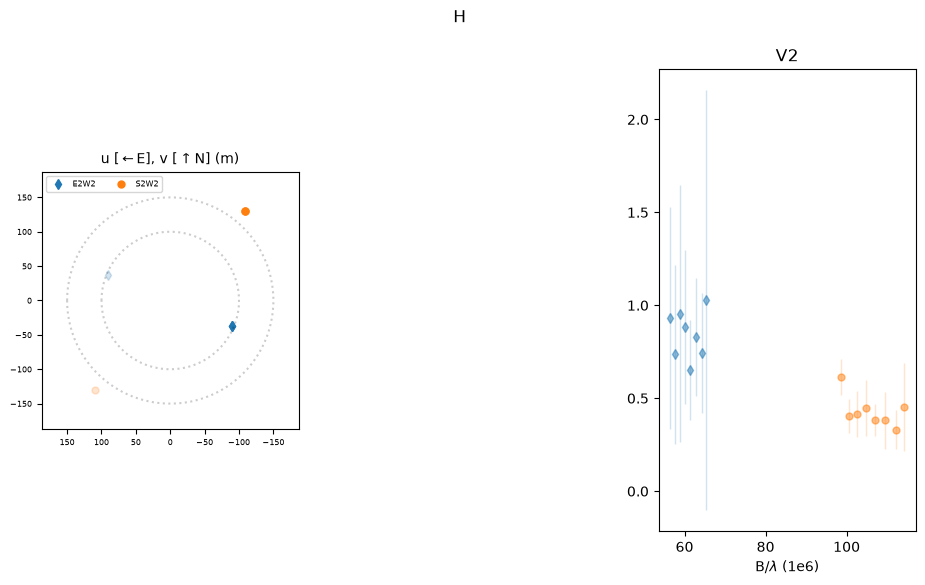

In [9]:
oi = pmoired.OI('MIRC_L2.2014Jul26.GL_586A.MIRCX_IDL.JDM.SPLIT.oifits') #binning=3)
oi.show(obs=['V2', 'T3PHI'])

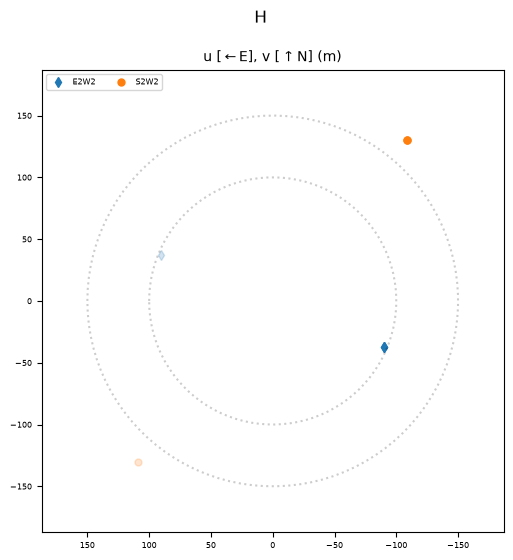

In [10]:
oi.show(obs=['']) # Show u, v only
# oi.show(obs=['V2']) 

In [11]:
plx = 51.1421 # mas from Gaia
R1 = 0.92 # From Strassmeier et al. 2013
R2 = 0.59 # From Strassmeier et al. 2013
R_Solar = 6.957e+8 # solar radii in meters
d_pc = 3.086e16 # pc in meters

data = oi.data[0]
print(data.keys())
print('\n')
print(f'Instrument: {data['insname']}')
print(f'Telescopes: {data['telescopes']}')
print(f'Baselines: {data['baselines']}')
print(f'Triangles: {data['triangles']}')
print('Mean MJD:', np.mean(data['MJD']))
print('Median MJD:', np.median(data['MJD']))
print('Duration of Observation (min)', 24*60*(np.max(data['MJD']) - np.min(data['MJD'])))

dict_keys(['insname', 'filename', 'targname', 'pipeline', 'LST', 'header', 'calibrated', 'WL', 'dWL', 'OI_VIS2', 'OI_VIS', 'telescopes', 'baselines', 'triangles', 'TELLURICS', 'configurations per MJD', 'MJD', 'recipes'])


Instrument: H_PRISM
Telescopes: ['E2', 'S2', 'W2']
Baselines: ['E2W2', 'S2W2']
Triangles: []
Mean MJD: 56864.23375829538
Median MJD: 56864.23375829538
Duration of Observation (min) 23.35556310019456


In [12]:
wl = data['WL']
d_wl = data['dWL']
print(f'Lambda (um)', wl)
print('Delta Lambda (um)', d_wl)
print('Spectral Resolution R', wl/d_wl)


wl_min = np.min(wl)
wl_max = np.max(wl)
wl_mean = np.mean(wl)
R_mean = np.mean(wl/d_wl)
print('Mean Wavelength (um):',wl_mean)
print('Mean R:', R_mean)


Lambda (um) [1.48849222 1.516368   1.55222051 1.58764408 1.62263871 1.65720473
 1.69134182 1.7234488 ]
Delta Lambda (um) [0.02388742 0.03186415 0.03563804 0.0352091  0.03478033 0.03435156
 0.03312203 0.03109193]
Spectral Resolution R [62.31279864 47.5885329  43.55516141 45.09187042 46.65392196 48.24249113
 51.06394663 55.43074546]
Mean Wavelength (um): 1.604919859232723
Mean R: 49.99243357089675


In [13]:
# Get min and max baseline lengths for each baseline

data = oi.data[0]

baseline_lengths = {}                
for b in data['baselines']:
    v = data['OI_VIS2'][b]
    baseline_lengths[b] = np.hypot(v['u'], v['v'])   
    #print(b, np.round(baseline_lengths[b], 2))


max_baselines = []
min_baselines = []
print("Baseline, Min (m), Max (m)")
for b in data['baselines']:
    print(b, baseline_lengths[b].min(), baseline_lengths[b].max())
    max_baselines.append(baseline_lengths[b].max())
    min_baselines.append(baseline_lengths[b].min())
    # usually go to 1/4 * lamda/longest baseline


# MAXIMUM BASELINE LENGTHS (in meters) FOR EACH BASELINE:
# BASELINE: W1S2; 247.98848075397257 m
# WAVELENGTH: 1.587e-06 m

Bmax = np.max(max_baselines) # meters
Bmin = np.min(min_baselines) # meters
wavelength = wl_mean / 1e6 # meters
fineness_factor = 1/4
max_resolution = fineness_factor * (wavelength / Bmax) * 206265e3 # in mas, 0.329997742239 mas
print('Max Baseline', Bmax, 'm')
print('Min Baseline', Bmin, 'm')
print('Fringe Spacing', (wavelength / Bmax) * 206265e3, 'mas')
print(f'Maximum Resolution for Search', max_resolution, "mas")

Baseline, Min (m), Max (m)
E2W2 97.37023590892382 97.37023590892382
S2W2 169.9303383961708 169.9303383961708
Max Baseline 169.9303383961708 m
Min Baseline 97.37023590892382 m
Fringe Spacing 1.948085303007301 mas
Maximum Resolution for Search 0.4870213257518253 mas


In [14]:
# Angular Diameter Calculation

theta_ud1 = 206265e3 * ((2 * R1 * R_Solar) / ((1/(plx*1e-3)) * d_pc))
theta_ud2 = 206265e3 * ((2 * R2 * R_Solar) / ((1/(plx*1e-3)) * d_pc))
print('UD1:',theta_ud1)
print('UD2:',theta_ud2)

UD1: 0.43757046743171013
UD2: 0.2806158432442489


setupFit> 0/H_PRISM: setting 'wl kernel':1.0 according to WL definition
22660 grid points not within constraints
Wed Nov  4 00:27:03 2026: running 80381 fits on 10 processes
Wed Nov  4 00:29:52 2026: [████████████████████████████████████████████████████████████]80381/80381   0s   leftt

Wed Nov  4 00:29:52 2026: it took 169.2s, 0.00s per fit on average [28501.5 fit/minute]
fits to be taken into account: 79178 / 80381
  1203 have uncertainties larger than the grid's step[s]
Wed Nov  4 00:29:53 2026: making list of unique minima...
Wed Nov  4 00:32:51 2026: [████████████████████████████████████████████████████████████]79178/79178   0s   left

unique minima: 459 / 79178 [~172.5 first guesses / minima]
  few unique minima -> grid too fine / Nfits too large?
Wed Nov  4 00:32:51 2026: linking unique minima to first guess(es)
Wed Nov  4 00:32:51 2026: done
------------
best fit: chi2= 0.07252750148598472
{'B,x': -34.300, # +/- 0.055
'B,y': 85.242, # +/- 0.052
'A,f': 1.0,
'A,ud':0.437570467431

/Users/ethanchen/ASTRO2/ASTRO399/.venv/lib/python3.14/site-packages/IPython/core/events.py:101: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)
/Users/ethanchen/ASTRO2/ASTRO399/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


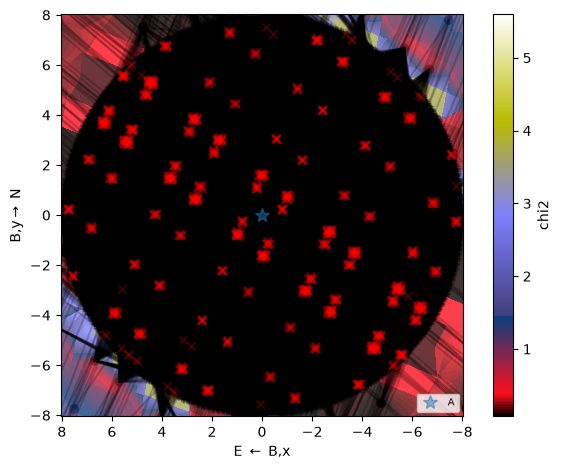

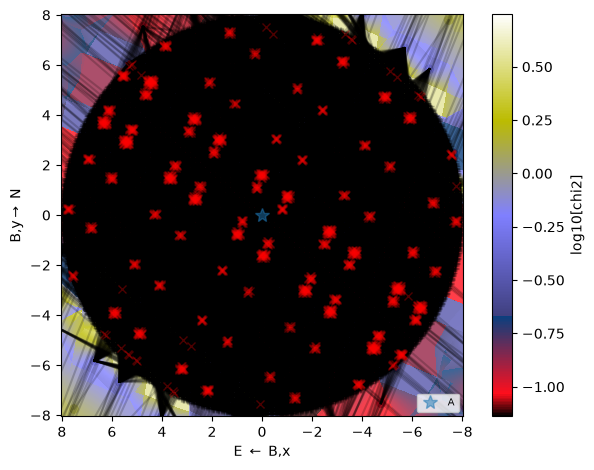

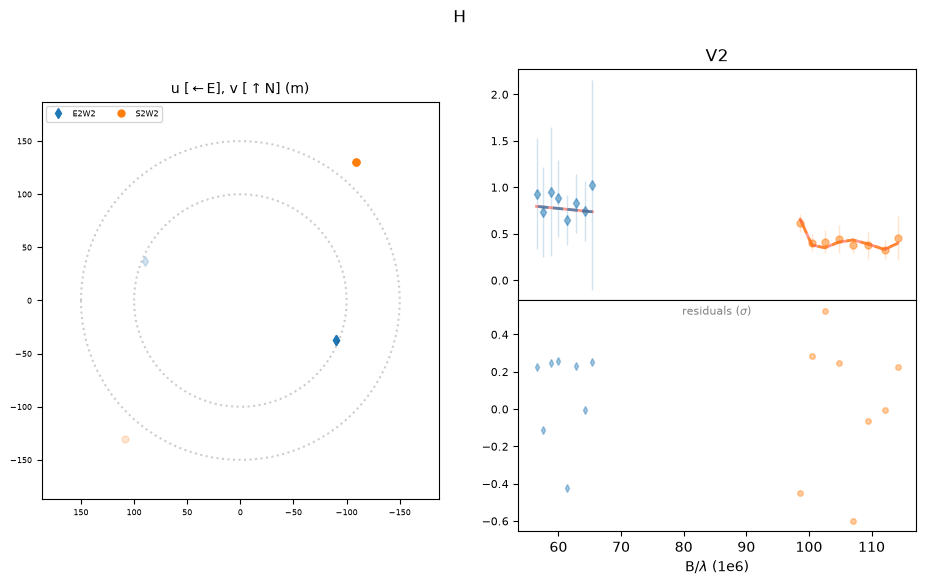

In [15]:
# Define model
# A at the origin, B offset (x East, y North, in mas)

maxsep1 = 8.0
step1 = 0.05  

param = {
    'A,f': 1.0,
    'A,ud': theta_ud1,      
    'A,x': 0.0, 'A,y': 0.0,
    'B,f': 0.2362529748,         # flux relative to A, initial guess at 2014-08-02 fit
    'B,ud': theta_ud2,      
    'B,x': 0.0, 'B,y': 0.0,
}

# Flux of B must be lower than A component
prior = [('B,f', '<', 1)]

# Constraints on B's position
# - Separation must be less than the maximum separation
constrain = [( 'np.sqrt(B,x**2+B,y**2)', '<', maxsep1)]


# parameters that will be fixed and not fitted
fixed = ['A,f', 'A,ud', 'A,x', 'A,y', 'B,ud', 'B,f'] # Fix B,f for bad fits


oi.setupFit({'obs': ['V2', 'T3PHI'], 'min relative error': {'V2': 0.01}})


# Grid search over B's position
expl = {'grid': {'B,x': (-maxsep1, maxsep1, step1), 'B,y': (-maxsep1, maxsep1, step1)}}
oi.gridFit(expl, model=param, doNotFit=fixed, constrain=constrain, prior=prior)

# -- show the grid result
oi.showGrid()

# -- show the log grid result
oi.showGrid(interpolate=True, logV=1)

# -- show the data and the best fit model
oi.show()

In [ ]:
# list the distinct minima it found in the unzoomed, best first
rows1 = []
for r in oi.grid:
    if r['bad']:
        continue
    b = r['best']
    rows1.append((r['chi2'], b['B,x'], b['B,y'], b['B,f']))
rows1.sort()

print('-----------------------------------------')
print('  chi2r    sep(mas)   PA(deg)   f_B/f_A')
for chi2, x, y, f in rows1[:]:
    print(f'{chi2}  {np.hypot(x, y)}  {np.degrees(np.arctan2(x, y)) % 360}  {f}')

-----------------------------------------
  chi2r    sep(mas)   PA(deg)   f_B/f_A
0.07252750148598472  91.88379259348322  338.0810973114665  0.2362529748
0.12266941192257046  5.246522339141637  164.6530403189093  0.2362529748
0.12266942620528018  4.846205294053313  330.11105200588196  0.2362529748


In [18]:
# The best fit position of component B, not zoomed in
x1 = oi.bestfit['best']['B,x']
y1 = oi.bestfit['best']['B,y']
pa1 = np.degrees(np.arctan2(x1, y1)) % 360
print(f'{x1}, {y1} mas, PA = {pa1} deg')

-34.29965639728988, 85.24180261110212 mas, PA = 338.0810973114665 deg


In [ ]:
# Refine the fit around the best fit point (x1, y1)

maxsep2 = 10
step2 = max_resolution        # half-width and step, in mas

expl = {'grid': {'B,x': (x1-maxsep2, x1+maxsep2, step2),
                 'B,y': (y1-maxsep2, y1+maxsep2, step2)}}

oi.gridFit(expl, model=oi.bestfit['best'], doNotFit=fixed, prior=prior)   # no constrain
oi.showGrid()
oi.showGrid(interpolate=True, logV=1)
oi.show()

In [ ]:
# list the distinct minima it found in the zoomed, best first
rows2 = []
for r in oi.grid:
    if r['bad']:
        continue
    b = r['best']
    rows2.append((r['chi2'], b['B,x'], b['B,y'], b['B,f']))
rows2.sort()

print('-----------------------------------------')
print('  chi2r    sep(mas)   PA(deg)   f_B/f_A')
for chi2, x, y, f in rows2[:8]:
    print(f'{chi2}  {np.hypot(x, y)}  {np.degrees(np.arctan2(x, y)) % 360}  {f}')

In [ ]:
# The best fit position of component B, zoomed in
x2 = oi.bestfit['best']['B,x']
y2 = oi.bestfit['best']['B,y']
pa2 = np.degrees(np.arctan2(x2, y2)) % 360
print(f'{x2}, {y2} mas, PA = {pa2} deg')

In [ ]:
# Refine the fit around the best fit point

x3 = x2
y3 = y2
maxsep3 = 1
step3 = 0.02        # half-width and step, in mas

expl = {'grid': {'B,x': (x2-maxsep3, x2+maxsep3, step3),
                 'B,y': (y2-maxsep3, y2+maxsep3, step3)}}

oi.gridFit(expl, model=oi.bestfit['best'], doNotFit=fixed, prior=prior)   # no constrain
oi.showGrid()
oi.showGrid(interpolate=True, logV=1)
oi.show()

In [ ]:
# list the distinct minima it found in the zoomed, best first
rows3 = []
for r in oi.grid:
    if r['bad']:
        continue
    b = r['best']
    rows3.append((r['chi2'], b['B,x'], b['B,y'], b['B,f']))
rows3.sort()

print('-----------------------------------------')
print('  chi2r    sep(mas)   PA(deg)   f_B/f_A')
for chi2, x, y, f in rows3[:8]:
    print(f'{chi2}  {np.hypot(x, y)}  {np.degrees(np.arctan2(x, y)) % 360}  {f}')

In [ ]:
# The best fit position of component B, zoomed in for a second time
x3 = oi.bestfit['best']['B,x']
y3 = oi.bestfit['best']['B,y']
pa3 = np.degrees(np.arctan2(x3, y3)) % 360
print(f'{x3}, {y3} mas, PA = {pa3} deg')

In [ ]:
# Refine Fit using the zoomed best fit, Bx_zoom, By_zoom
oi.doFit(oi.bestfit['best'], doNotFit=fixed)
oi.showFit()

In [ ]:
# Separation and position angle
b = oi.bestfit['best']
x, y = b['B,x'], b['B,y']
sep = np.hypot(x, y)
pa = np.degrees(np.arctan2(x, y)) % 360
print(f"sep = {sep} mas, PA = {pa} deg, f_B/f_A = {b['B,f']}")
print(x, y)

In [ ]:
# Uncertainties

oi.bootstrapFit(Nfits=500)
oi.showBootstrap()

In [ ]:
# BEST FIT PARAMETERS AND UNCERTAINTIES

# Separation and position angle
b = oi.bestfit['best']
x, y = b['B,x'], b['B,y']
sep = np.hypot(x, y)
pa = np.degrees(np.arctan2(x, y)) % 360
print(f"sep = {sep} mas, PA = {pa} deg, f_B/f_A = {b['B,f']}")
print(x, y)

In [ ]:
# Summary of all the Grid Fits

print(f"Grid Size: {2*maxsep1} x {2*maxsep1} mas; Step = {step1} mas")
print(f"    Bx: {x1} mas; By: {y1} mas; PA = {pa1} deg")
print(f"Grid Size: {2*maxsep2} x {2*maxsep2} mas; Step = {step2} mas")
print(f"    Bx: {x2} mas; By: {y2} mas; PA = {pa2} deg")
print(f"Grid Size: {2*maxsep3} x {2*maxsep3} mas; Step = {step3} mas")
print(f"    Bx: {x3} mas; By: {y3} mas; PA = {pa3} deg")

In [19]:
# More readable grids without the movement of the fits plotted
# The dofit model (not using grid fit and keeping Bx, By fixed) searches in an area centered around the best fit of the last gridfit model (x3, y3)


start = dict(oi.bestfit['best']) # includes x3, y3, B,f and the fixed params
start['B,x'] = x1
start['B,y'] = y1

x1_2, y1_2 = x1, y1

maxsep1_2 = 8
step1_2 = 0.1       # half-width and step, in mas

xs = np.arange(x1_2-maxsep1_2, x1_2+maxsep1_2+step1_2/2, step1_2)
ys = np.arange(y1_2-maxsep1_2, y1_2+maxsep1_2+step1_2/2, step1_2)
frozen = fixed + ['B,x', 'B,y'] # B,f is still fitted at each point

chi2 = np.zeros((len(ys), len(xs)))

progress = 0

for j, y in enumerate(ys):
    for i, x in enumerate(xs):
        p = dict(start); p['B,x'], p['B,y'] = x, y
        oi.doFit(p, doNotFit=frozen, prior=prior, verbose=0)
        chi2[j, i] = oi.bestfit['chi2']

    progress += len(xs)
    print(f'{progress}/{len(xs)*len(ys)}')

oi.doFit(start, doNotFit=fixed, verbose=0)   # restore oi.bestfit

161/25921
322/25921
483/25921
644/25921
805/25921
966/25921
1127/25921
1288/25921
1449/25921
1610/25921
1771/25921
1932/25921
2093/25921
2254/25921
2415/25921
2576/25921
2737/25921
2898/25921
3059/25921
3220/25921
3381/25921
3542/25921
3703/25921
3864/25921
4025/25921
4186/25921
4347/25921
4508/25921
4669/25921
4830/25921
4991/25921
5152/25921
5313/25921
5474/25921
5635/25921
5796/25921
5957/25921
6118/25921
6279/25921
6440/25921
6601/25921
6762/25921
6923/25921
7084/25921
7245/25921
7406/25921
7567/25921
7728/25921
7889/25921
8050/25921
8211/25921
8372/25921
8533/25921
8694/25921
8855/25921
9016/25921
9177/25921
9338/25921
9499/25921
9660/25921
9821/25921
9982/25921
10143/25921
10304/25921
10465/25921
10626/25921
10787/25921
10948/25921
11109/25921
11270/25921
11431/25921
11592/25921
11753/25921
11914/25921
12075/25921
12236/25921
12397/25921
12558/25921
12719/25921
12880/25921
13041/25921
13202/25921
13363/25921
13524/25921
13685/25921
13846/25921
14007/25921
14168/25921
14329/25921


Text(0, 0.5, 'B,y (mas, N →)')

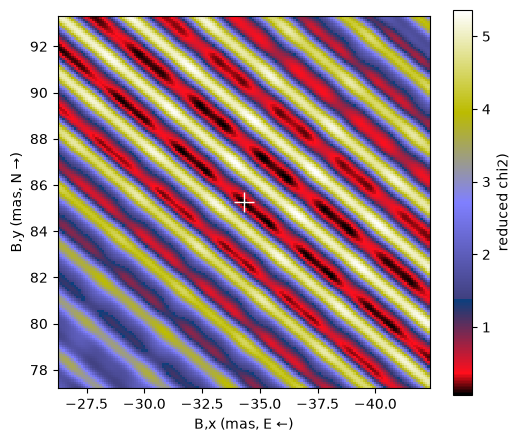

In [21]:

plt.figure(figsize=(6, 5))

plt.pcolormesh(xs, ys, chi2, cmap='gist_stern')

plt.plot(x1, y1, marker='+', color='w', ms=14, mew = 1)


plt.colorbar(label='reduced chi2)')
plt.gca().invert_xaxis(); plt.gca().set_aspect('equal')
plt.xlabel('B,x (mas, E ←)'); plt.ylabel('B,y (mas, N →)')



In [23]:
# Print the n grid points with the lowest chi2, with their B,x and B,y

n = 1000                                           # how many to print

order = np.argsort(chi2, axis=None)              # flat indices, lowest chi2 first
order = order[np.isfinite(chi2.flat[order])]     # drop NaN (uncomputed) points

# print(f'Top {min(n, len(order))} lowest chi2 grid points')
# print('  rank    chi2r       B,x        B,y     sep(mas)   PA(deg)')
# for rank, k in enumerate(order[:n], start=1):
#     j, i = np.unravel_index(k, chi2.shape)       # row (y), column (x)
#     x, y = xs[i], ys[j]
#     print(f'{rank}  {chi2[j, i]}  {x}  {y}  {np.hypot(x, y)}  {np.degrees(np.arctan2(x, y)) % 360}')

print('  rank    chi2r      sep(mas)   PA(deg)')
for rank, k in enumerate(order[:n], start=1):
    j, i = np.unravel_index(k, chi2.shape)       # row (y), column (x)
    x, y = xs[i], ys[j]
    print(f'{rank}  {chi2[j, i]} {np.hypot(x, y)}  {np.degrees(np.arctan2(x, y)) % 360}')

  rank    chi2r      sep(mas)   PA(deg)
1  0.06622076222633641 91.88379259348277  338.08109731146646
2  0.07070940717997962 91.46953230850272  337.2313974535881
3  0.07267260039038712 93.58467860786197  337.31011123224744
4  0.0730469600123109 90.50552260781276  335.1742456247878
5  0.07367614755970708 91.82844282747801  337.9999217694523
6  0.07494627461706589 91.52313243098153  337.3133495356905
7  0.07789628191838853 93.53108382187204  337.22996362710353
8  0.07808865377338232 95.12924781046924  340.08744115323424
9  0.07845410992264217 93.94508843744835  338.0610246449426
10  0.07887867533460262 93.98249609794075  338.00447522070647
11  0.07908073942169795 93.01041371580429  340.07325935769643
12  0.0792866868486655 94.03785409101066  338.0837886523966
13  0.08011377994243384 92.57180757078497  339.38079785157726
14  0.08041160050322808 90.45684713315264  335.09016437407985
15  0.08165388724627551 91.93932657250063  338.1621749513701
16  0.08289216317927335 92.60781745592861  335.1

In [ ]:
# To scale, based off calculated uds
disp = dict(oi.bestfit['best'])
oi.showModel(disp, imFov=1.2*maxsep1, imPix=0.1, imPow=0.5, showSED=False)

In [ ]:
# Not to scale
disp = dict(oi.bestfit['best'])
disp['A,ud'] = 5      # display size only, not measured
disp['B,ud'] = 4
oi.showModel(disp, imFov=0.5*maxsep1, imPix=0.6, imPow=1, showSED=False)